# 04 · Optimización y contraste con Semana 5

Resultados reales disponibles de tres configuraciones. Este notebook no transforma 100 épocas en 100 ensayos independientes ni atribuye una búsqueda Optuna que no se ha realizado.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib
from html import escape
from IPython.display import display, Markdown, HTML, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paths.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
def load(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def table(rows):
    if not rows:
        return display(Markdown("Sin filas."))
    keys = list(rows[0])
    head = "".join("<th>" + escape(str(k)) + "</th>" for k in keys)
    body = "".join("<tr>" + "".join("<td>" + escape(str(r.get(k, ""))) + "</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML("<table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table>"))
print("Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.")


Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.


In [2]:
from src.comparar_experimentos import main as comparar
comparar()
report=load("results/metrics/comparacion_experimentos.json")
table([{k:r[k] for k in ["experiment","weight_decay","degrees","best_logged_epoch","map50_95","improvement_over_baseline_pp"]} for r in report["experiments"]])

{"experiment": "yolov9t_baseline", "epochs": 100, "weight_decay": 0.0005, "degrees": 0.0, "best_logged_epoch": 80, "precision": 0.97499, "recall": 0.97314, "map50": 0.98289, "map50_95": 0.88673, "last_map50_95": 0.88078, "recorded_training_minutes": 87.18966666666667, "reevaluated_best_epoch": 78, "reevaluated_val_map50_95": 0.8869937846554071, "reevaluated_train_map50_95": 0.926800569152158, "reevaluated_gap_pp": 3.98067844967509, "improvement_over_baseline_pp": 0.0}
{"experiment": "yolov9t_regularizacion", "epochs": 100, "weight_decay": 0.001, "degrees": 0.0, "best_logged_epoch": 82, "precision": 0.97822, "recall": 0.96825, "map50": 0.98242, "map50_95": 0.89057, "last_map50_95": 0.88368, "recorded_training_minutes": 73.05216666666666, "reevaluated_best_epoch": 84, "reevaluated_val_map50_95": 0.8901742933474285, "reevaluated_train_map50_95": 0.9301414774092223, "reevaluated_gap_pp": 3.996718406179378, "improvement_over_baseline_pp": 0.38399999999999546}
{"experiment": "yolov9t_rotacio

experiment,weight_decay,degrees,best_logged_epoch,map50_95,improvement_over_baseline_pp
yolov9t_baseline,0.0005,0.0,80,0.88673,0.0
yolov9t_regularizacion,0.001,0.0,82,0.89057,0.38399999999999546
yolov9t_rotacion,0.0005,5.0,89,0.88884,0.21099999999999453


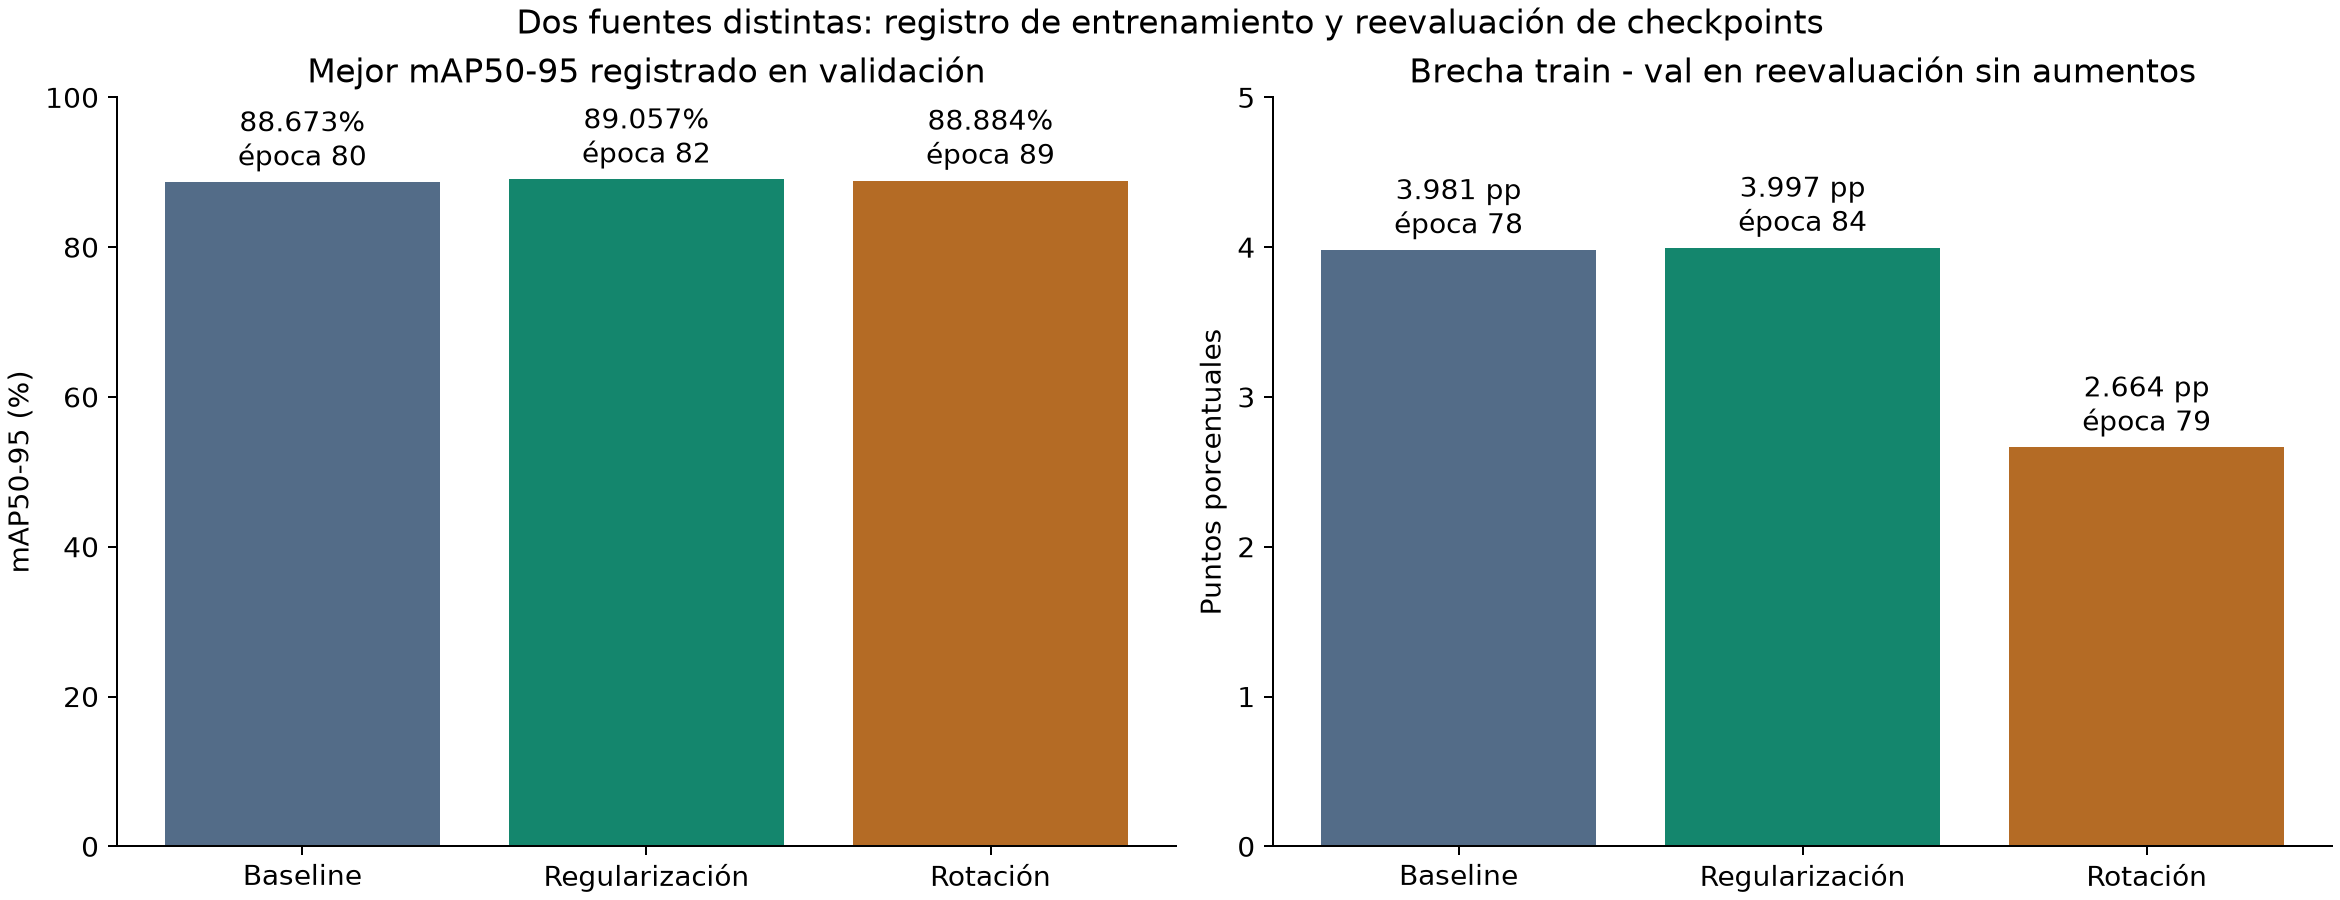

In [3]:
display(Image(filename=str(ROOT/"results/figures/comparacion_modelos.png"),width=1000))

## Interpretación

La regularización aumenta mAP50–95 de validación en 0,384 puntos porcentuales. Una corrida por configuración no establece significancia. La rotación reduce la brecha train/val en las épocas reevaluadas, sin obtener el máximo mAP50–95. No se utiliza test para seleccionar hiperparámetros.

In [4]:
import itertools
observed={(r["weight_decay"],r["degrees"]) for r in report["experiments"]}
grid=set(itertools.product([0.0005,0.001],[0.0,5.0]))
print("Combinaciones observadas:",sorted(observed))
print("Combinación ausente:",sorted(grid-observed))
print("No se ajusta un sustituto con tres observaciones ni se fabrican PDP/interacciones.")

Combinaciones observadas: [(0.0005, 0.0), (0.0005, 5.0), (0.001, 0.0)]
Combinación ausente: [(0.001, 5.0)]
No se ajusta un sustituto con tres observaciones ni se fabrican PDP/interacciones.


## Qué pide el material recibido

`Semana5_Workshops_semana5 (1).ipynb` contiene estrés controlado y 60 ensayos Optuna en Random Forest, importancia, slice/contorno, dependencia parcial mediante un sustituto y evaluación final separada. Adaptar ese método al detector exige nuevos experimentos o un estudio de inferencia claramente separado del entrenamiento. Está pendiente; este notebook no cierra ese requisito. Véase `docs/semana5_brechas.md`.

## Estudio ampliado de Semana 5

Las secciones anteriores describen las tres corridas históricas. Esta sección consulta el nuevo estudio autorizado el 20/10/2026; su estado impide confundir un entrenamiento en curso con resultados completos. El diseño está en `docs/estudio_semana5.md`. Test no participa en este estudio.

Los ensayos cortos usan 35% de train y 12 épocas. Su métrica no es comparable directamente con las corridas de 100 épocas. Los ajustes finales comparten SGD y presupuesto; una semilla no prueba significancia entre entrenamientos.

{'stage': 'completado',
 'updated': '2026-10-21T03:20:11-0500',
 'best_trial': 0,
 'test_used': False}

Estudio completado: True
Estados de ensayos: {'COMPLETE': 17, 'PRUNED': 43}


number,state,value,weight_decay,degrees,seconds
0,COMPLETE,0.8687811676022064,0.0005,0.0,335.482069
1,COMPLETE,0.862096123834198,0.001,0.0,327.324894
2,COMPLETE,0.8383539105261223,0.0005,5.0,331.431045
3,COMPLETE,0.848334988374986,0.001,5.0,328.583936
4,COMPLETE,0.8347438904829876,0.0003574712922600243,9.50714306409916,336.330641
5,COMPLETE,0.8440505972298056,0.001205712628744377,5.986584841970366,328.498712
6,COMPLETE,0.85517,0.0001700037298921101,1.5599452033620265,326.656777
7,COMPLETE,0.84452,0.00012184186502221769,8.661761457749352,322.469026
8,COMPLETE,0.84167,0.0007725378389307352,7.080725777960454,311.440718
9,COMPLETE,0.84735,0.00010725209743172001,9.699098521619943,312.332355


seleccion


{'trial': 0,
 'proxy_value': 0.8687811676022064,
 'params': {'weight_decay': 0.0005, 'degrees': 0.0},
 'selection': 'Mayor mAP50-95 proxy; no se elige con robustez ni test'}

...

{'completed': 17,
 'cv_r2': [0.7760904272425331,
  0.9817656874747385,
  0.8402621308250846,
  0.6822874973247244,
  0.40319295937687616],
 'cv_mae': [0.0027453995856878965,
  0.0010339524070834272,
  0.003039091440601216,
  0.004142796186066611,
  0.00484526536883149],
 'features': ['log10(weight_decay)', 'degrees'],
 'permutation_training_descriptive': [0.013375221087264074,
  1.6244820063314118],
 'optuna_fanova': {'degrees': 0.9677186897137674,
  'weight_decay': 0.03228131028623259},
 'warning': 'PDP e interacciones exploratorias; no causales. Revisar R2 de CV y cobertura; no extrapolar al ajuste de 100 épocas.'}

final_referencia


{'checkpoint': '.model-cache\\semana5\\training\\final_referencia\\weights\\best.pt',
 'sha256': '66f2fe928324e1d33048af443e8bbfaa66a810aab0b3c9158bf71d85aa4cdec3',
 'params': {'weight_decay': 0.0005, 'degrees': 0.0},
 'epochs': 100,
 'validation': {'metrics/precision(B)': 0.9777533139708665,
  'metrics/recall(B)': 0.9659455373741088,
  'metrics/mAP50(B)': 0.9889394505129431,
  'metrics/mAP50-95(B)': 0.8901083528244627}}

final_optimizado


{'checkpoint': '.model-cache\\semana5\\training\\final_optimizado\\weights\\best.pt',
 'sha256': '4a9f79411b012534d9ff5a338fb76de97bccb1c1e925b1d47559b756b15802a5',
 'params': {'weight_decay': 0.0005, 'degrees': 0.0},
 'epochs': 100,
 'validation': {'metrics/precision(B)': 0.9777533139708665,
  'metrics/recall(B)': 0.9659455373741088,
  'metrics/mAP50(B)': 0.9889394505129431,
  'metrics/mAP50-95(B)': 0.8901083528244627}}

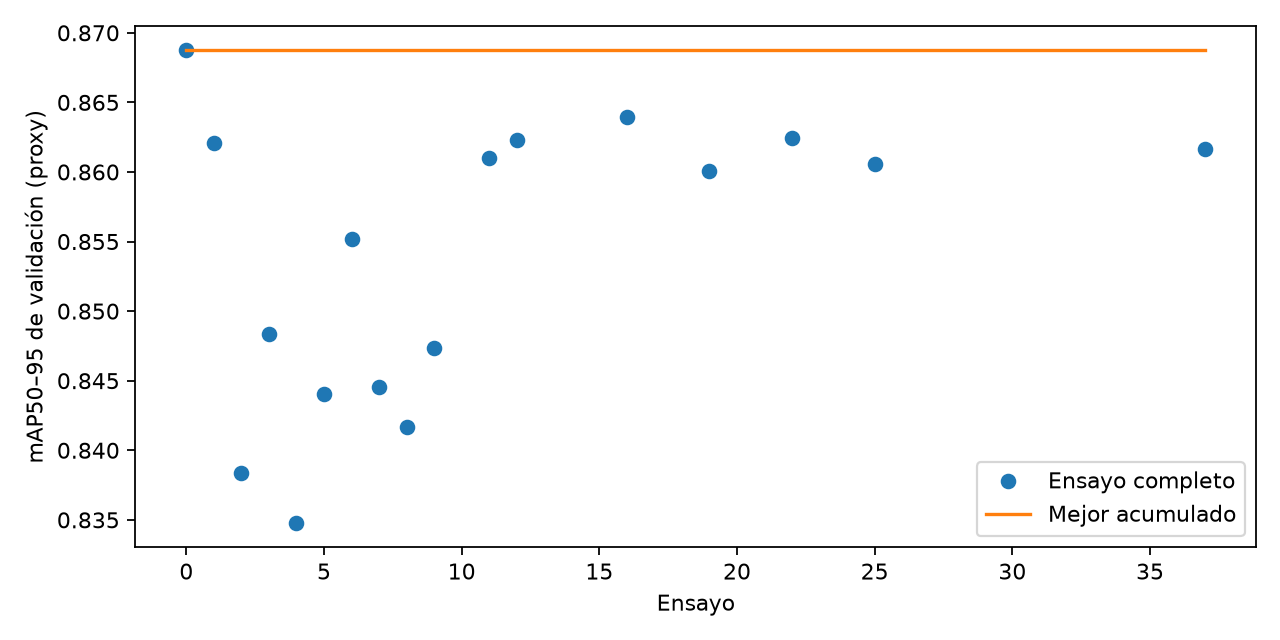

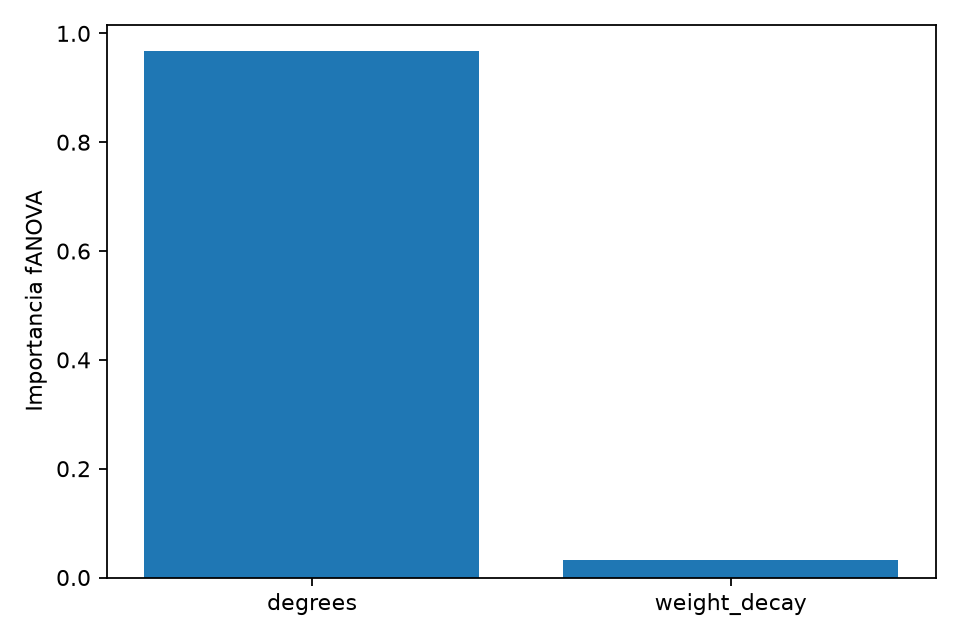

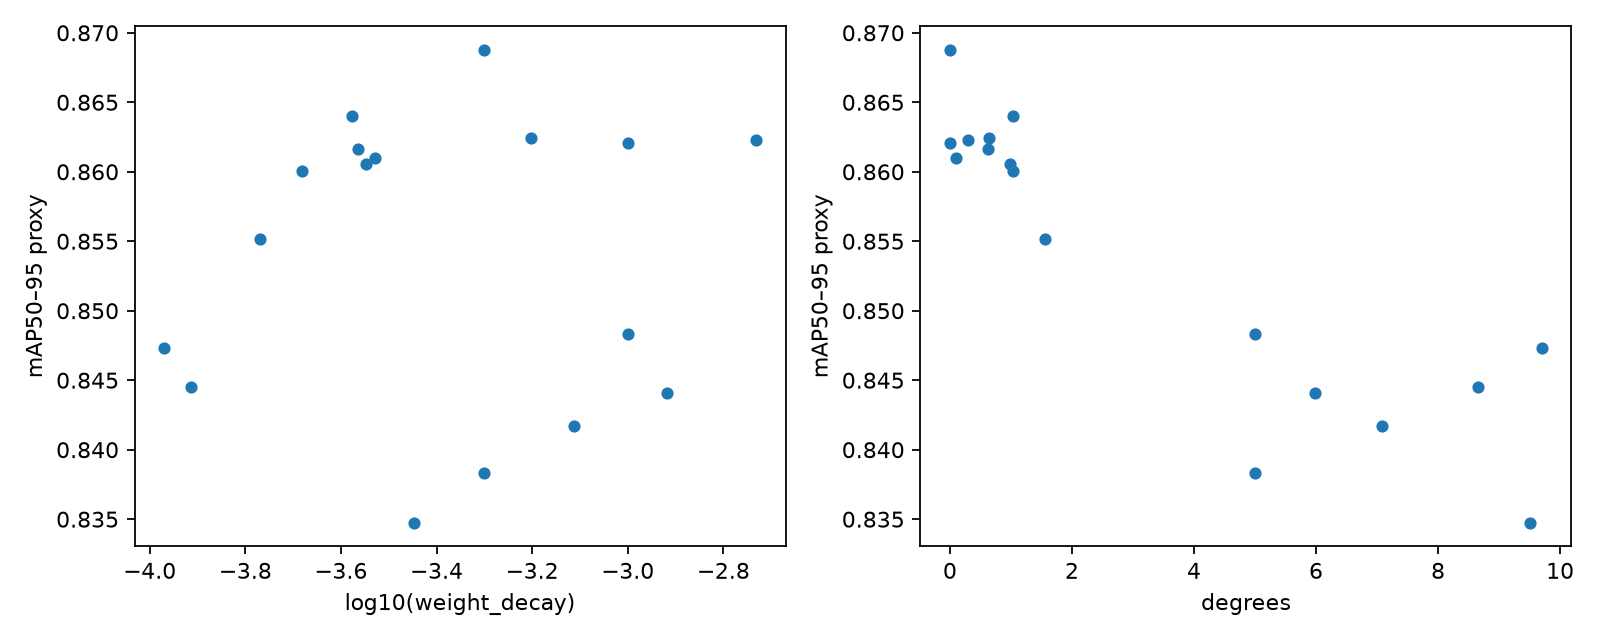

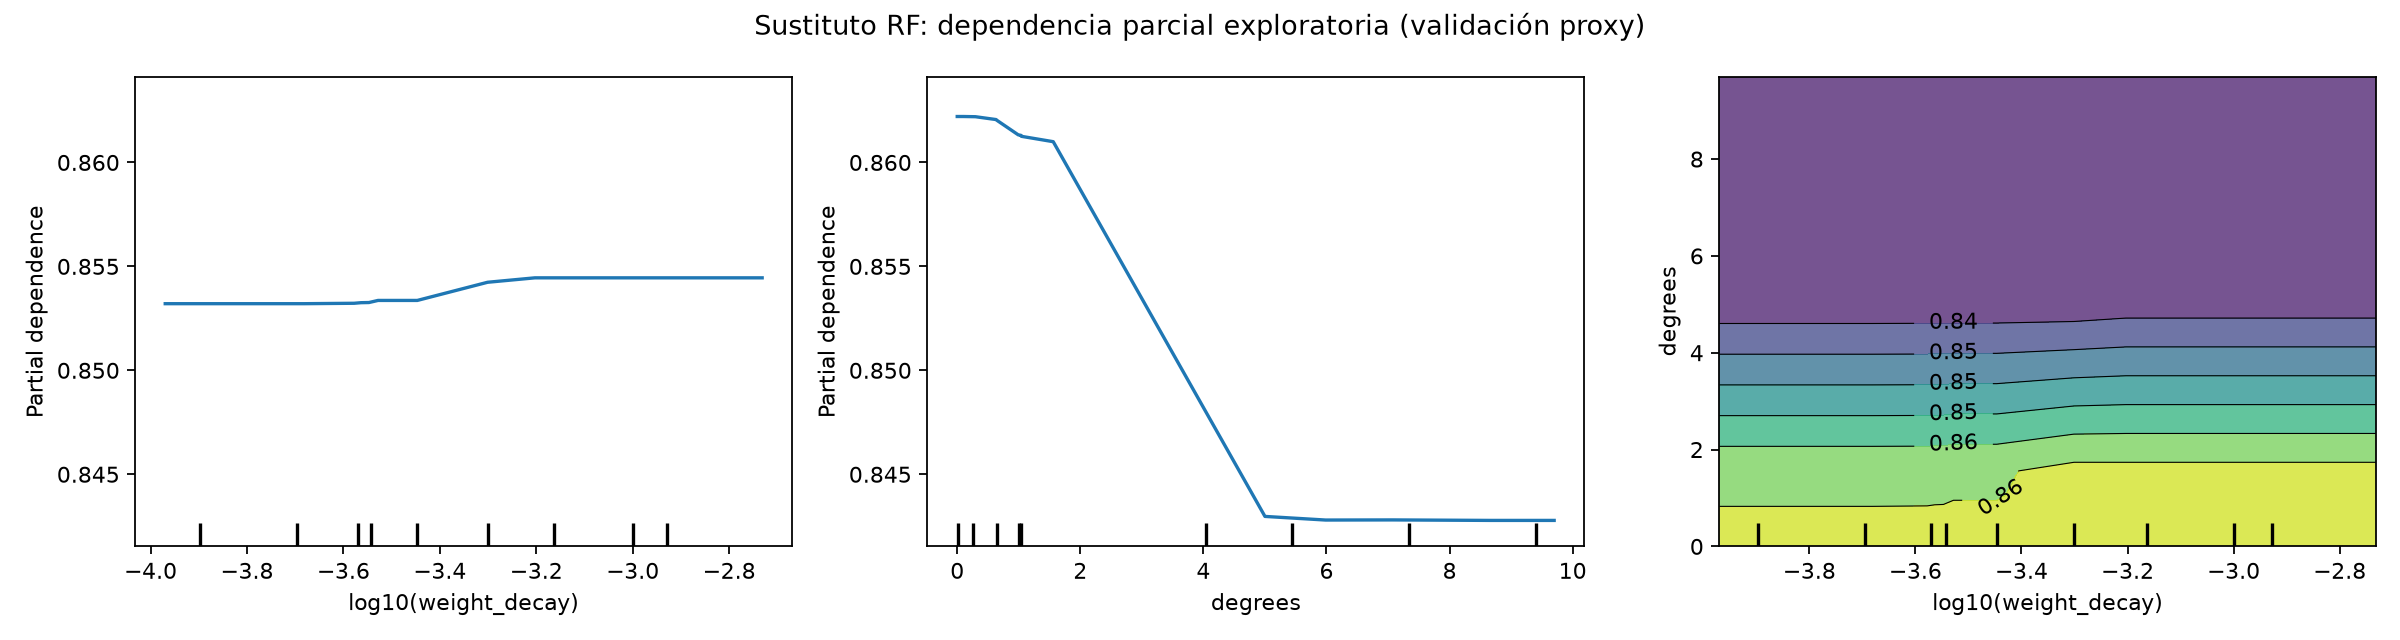

model,scenario,n_images,precision,recall,f1,recall_ci95,recall_drop_vs_clean_ci95_paired,small_recall
referencia,limpio,733,0.9536266349583828,0.9792429792429792,0.9662650602409638,"[0.9694367176113936, 0.9877899877899878]","[0.0, 0.0]",0.9491525423728814
referencia,ruido_10,733,0.9591346153846154,0.9743589743589743,0.966686856450636,"[0.9636363636363636, 0.9843378205964652]","[0.001206272617611634, 0.009779951100244544]",0.9389830508474576
referencia,ruido_25,733,0.9887005649717514,0.6410256410256411,0.7777777777777778,"[0.608381731029984, 0.6732685612700922]","[0.3071231453209609, 0.36983517922960174]",0.5932203389830508
referencia,blur_5,733,0.990450204638472,0.8864468864468864,0.9355670103092784,"[0.8665825248194946, 0.9081888893275951]","[0.07388935342555399, 0.11097711680691874]",0.7796610169491526
referencia,blur_9,733,0.9847560975609756,0.39438339438339437,0.5632083696599826,"[0.36199239828272084, 0.42734413628289414]","[0.5514342857390812, 0.6176497787771089]",0.3389830508474576
referencia,oscuro_05,733,0.9580838323353293,0.9768009768009768,0.9673518742442564,"[0.9664670658682635, 0.986469864698647]","[-0.002436053593179002, 0.007326007326007303]",0.9423728813559322
referencia,claro_15,733,0.9569377990430622,0.9768009768009768,0.9667673716012085,"[0.9659781287970839, 0.9865525672371638]","[-0.002418452881121716, 0.007343941248470043]",0.9423728813559322
referencia,resolucion_05,733,0.9803407601572739,0.9133089133089133,0.9456384323640961,"[0.895179035570171, 0.931930693069307]","[0.04999999999999993, 0.08212560386473433]",0.8033898305084746
referencia,oclusion_10,733,0.6431642304385211,0.9133089133089133,0.7547931382441978,"[0.8934124031349067, 0.9332550049832843]","[0.048994090710590917, 0.08251231527093594]",0.8372881355932204
optimizado,limpio,733,0.9536266349583828,0.9792429792429792,0.9662650602409638,"[0.9694367176113936, 0.9877899877899878]","[0.0, 0.0]",0.9491525423728814


Bootstrap pareado por imagen; no mide incertidumbre entre entrenamientos.
Val se reutiliza para desarrollo. No es una evaluación independiente de test.


In [5]:
study_dir = ROOT / "results/semana5"
if not (study_dir / "estado.json").exists():
    print("No hay estado guardado: estudio todavía sin iniciar.")
else:
    state = load("results/semana5/estado.json")
    display(state)
    print("Estudio completado:", state["stage"] == "completado")
    if (study_dir / "ensayos.json").exists():
        trials = load("results/semana5/ensayos.json")
        from collections import Counter
        print("Estados de ensayos:", dict(Counter(t["state"] for t in trials)))
        table([{k:v for k,v in t.items() if k != "intermediate"} for t in trials])
    for name in ["seleccion", "sustituto", "final_referencia", "final_optimizado"]:
        if (study_dir / (name+".json")).exists():
            print(name); display(load("results/semana5/"+name+".json"))
    for name in ["historial", "importancia", "slice", "pdp_interaccion"]:
        if (study_dir / (name+".png")).exists():
            display(Image(filename=str(study_dir/(name+".png")), width=1000))
    if (study_dir / "robustez_resumen.json").exists():
        table(load("results/semana5/robustez_resumen.json"))
        print("Bootstrap pareado por imagen; no mide incertidumbre entre entrenamientos.")
    print("Val se reutiliza para desarrollo. No es una evaluación independiente de test.")